# Fabry–Perot interferometers, interference filters and the Lyot filter

Two-beam interference (the Michelson of notebook 111) turns a spectrum
into slow cosine fringes. **Multiple-beam** interference between two
highly reflecting mirrors turns it into sharp peaks: a Fabry–Perot
transmits only wavelengths that fit an integer number of half waves into
its spacing, and resolves lines a thousand times finer than its free
spectral range. Shrink the spacing to a few half waves of coating material
and the same physics makes the narrow band **interference filters** that
sit in front of almost every spectroscopic camera. Replace the mirrors by
polarizers and the spacing by birefringent plates and you get the
**Lyot filter**, with which the Sun is watched in a single spectral line.

The sections are:

1. the Airy function as a spectrometer: free spectral range, finesse
   and resolving power of an etalon with silver and with dielectric
   mirrors, computed with the transfer matrices of `thin_films`, and the
   finesse lost to mirrors that are not flat,
2. scanning and imaging Fabry–Perots: the hyperfine structure of the
   sodium D2 line, the overlapping orders that need a prefilter, and the
   Zeeman effect seen in the rings of an imaging etalon,
3. interference filters: an all-dielectric Fabry–Perot of a few layers,
   its bandwidth, the shift to the blue with the angle, and what a
   converging beam does to it, and the linear variable filter,
4. the Lyot filter and the Šolc filter, as Jones matrix products
   (`polarization.jones`), a 0.03 nm filter for the solar Hα line,
5. a comparison of resolving power and acceptance (étendue) of the
   instruments of notebooks 110, 111 and 113.

The closed forms are in `pyoptics.spectroscopy` (`airy_transmission()`,
`reflective_finesse()`, `effective_finesse()`, `free_spectral_range()`,
`lyot_transmission()`).

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import thin_films as tf
from pyoptics import spectroscopy as spc
from pyoptics.polarization import jones

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
C_LIGHT = 299792458.0

## 1. The Airy function as a spectrometer

Light bouncing between two mirrors of reflectance $R$ and absorptance
$A$, a distance $d$ apart in a medium of index $n$, picks up the round
trip phase $\delta = 4\pi n d\cos\theta/\lambda$ (plus the phases of the
mirrors). The transmitted waves add to the **Airy function**

$$T = \left(\frac{1 - R - A}{1 - R}\right)^2\frac{1}{1 + F\sin^2(\delta/2)},
  \qquad F = \frac{4R}{(1 - R)^2}.$$

The peaks repeat every **free spectral range**
$\Delta\tilde\nu = 1/(2nd)$ (in wavelength $\lambda^2/2nd$); their width
is the FSR divided by the **finesse** $\mathcal F = \pi\sqrt R/(1 - R)$,
the effective number of round trips. In the order $m = 2nd/\lambda$ the
resolving power is $R_\mathrm{FP} = m\mathcal F$, huge for a modest
instrument: a 5 mm air gap at 589 nm is the order 17 000, and with a
finesse of 30 that is a resolving power of half a million.

Below, an etalon of two fused silica plates with 35 nm silver mirrors
(index of silver at 589 nm, $0.059 + 3.59i$) or with dielectric mirrors
($(HL)^5H$ quarter-wave stacks of TiO₂ and SiO₂), facing each other across
a 5 mm air gap, is computed as a whole stack with `thin_films`, and
compared with the Airy function for the reflectance and absorptance of a
single mirror.

silver 35 nm      : R = 0.8786, A = 0.0216, peak T = 0.676 (Airy 0.676), FSR 0.03473 nm (λ²/2d = 0.03473), finesse 24.2 (π√R/(1−R) = 24.3), resolving power 4.11e+05
(HL)⁵H dielectric : R = 0.9910, A = 0.0000, peak T = 0.997 (Airy 1.000), FSR 0.03473 nm (λ²/2d = 0.03473), finesse 343.8 (π√R/(1−R) = 347.2), resolving power 5.83e+06


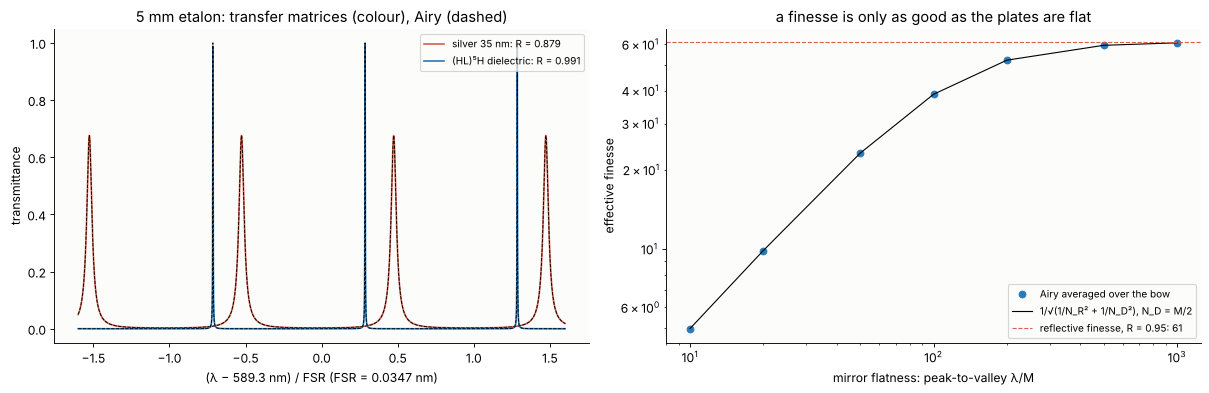

λ/10   : finesse   5.0, quadrature sum   5.0
λ/20   : finesse   9.9, quadrature sum   9.9
λ/50   : finesse  23.1, quadrature sum  23.1
λ/100  : finesse  38.7, quadrature sum  38.7
λ/200  : finesse  52.2, quadrature sum  52.2
λ/500  : finesse  59.5, quadrature sum  59.5
λ/1000 : finesse  60.8, quadrature sum  60.8


In [2]:
N_AG = 0.059 + 3.586j
N_H, N_L, N_G = 2.35, 1.46, 1.458           # TiO2, SiO2, fused silica
LAM0 = 589.3
GAP = 5e6                                   # nm


def stack_RTA(n_layers, t_layers, lam, n_in=1.0, n_sub=N_G, angle=0.0, pol="s"):
    n_c = np.array(n_layers, dtype=complex)
    return tf.R_T_A_coeffs(angle, n_c.real, n_c.imag, np.array(t_layers, float), n_in, 0.0,
                           n_sub.real if np.iscomplexobj(n_sub) else n_sub, 0.0, pol, lam)


def dielectric_mirror(pairs, lam0=LAM0):
    """(HL)^pairs H quarter waves, from the gap side."""
    n = [N_H, N_L]*pairs + [N_H]
    t = [lam0/(4*x) for x in n]
    return n, t


mirrors = {"silver 35 nm": ([N_AG], [35.0]), "(HL)⁵H dielectric": dielectric_mirror(5)}
fsr_nm = LAM0**2/(2*GAP)
lam = LAM0 + np.linspace(-1.6, 1.6, 6401)*fsr_nm
results = {}
for name, (n_m, t_m) in mirrors.items():
    R1, T1, A1 = stack_RTA(n_m, t_m, LAM0, n_in=1.0, n_sub=N_G)   # one mirror, seen from the gap
    n_all = list(n_m[::-1]) + [1.0] + list(n_m)
    t_all = list(t_m[::-1]) + [GAP] + list(t_m)
    T = np.array([stack_RTA(n_all, t_all, l, n_in=N_G, n_sub=N_G)[1] for l in lam])
    results[name] = (R1, A1, T)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for (name, (R1, A1, T)), c in zip(results.items(), (RED, BLUE)):
    peaks = np.where((T[1:-1] > T[:-2]) & (T[1:-1] >= T[2:]))[0] + 1
    peaks = peaks[T[peaks] > 0.5*T.max()]
    fsr_meas = np.mean(np.diff(lam[peaks]))
    i0 = peaks[np.argmin(np.abs(lam[peaks] - LAM0))]
    win = slice(i0 - 1000, i0 + 1000)
    fw = spc.fwhm(lam[win], T[win])
    print("{:18s}: R = {:.4f}, A = {:.4f}, peak T = {:.3f} (Airy {:.3f}), FSR {:.5f} nm (λ²/2d = {:.5f}), "
          "finesse {:.1f} (π√R/(1−R) = {:.1f}), resolving power {:.2e}".format(
              name, R1, A1, T[i0], ((1 - R1 - A1)/(1 - R1))**2, fsr_meas, fsr_nm, fsr_meas/fw,
              spc.reflective_finesse(R1), LAM0/fw))
    ax[0].plot((lam - LAM0)/fsr_nm, T, color=c, label="{}: R = {:.3f}".format(name, R1))
    # the Airy function with the single-mirror R and A, aligned on the peak
    delta = 2*np.pi*(lam - lam[i0])/fsr_meas
    ax[0].plot((lam - LAM0)/fsr_nm, spc.airy_transmission(delta, R1, A1), "--", color="k", lw=0.8)
    results[name] = (R1, A1, T, fsr_meas/fw)
ax[0].set_xlabel("(λ − 589.3 nm) / FSR (FSR = {:.4f} nm)".format(fsr_nm))
ax[0].set_ylabel("transmittance")
ax[0].set_title("5 mm etalon: transfer matrices (colour), Airy (dashed)")
ax[0].legend(fontsize=9)

# finesse lost to bowed mirrors: thickness uniformly spread over lambda/M
R_m = 0.95
NR = spc.reflective_finesse(R_m)
Ms = np.array([10, 20, 50, 100, 200, 500, 1000])
phase = np.linspace(-np.pi, np.pi, 20001)
fin = []
for M in Ms:
    spread = np.linspace(-1, 1, 801)*2*np.pi/M       # δ spread: Δd = λ/(2M) each way -> 4π Δd/λ
    T_avg = np.mean(spc.airy_transmission(phase[None, :] + spread[:, None], R_m), axis=0)
    fin.append(2*np.pi/spc.fwhm(phase, T_avg))
ax[1].loglog(Ms, fin, "o", color=BLUE, label="Airy averaged over the bow")
ax[1].loglog(Ms, spc.effective_finesse(NR, Ms/2), "k-", lw=1, label="1/√(1/N_R² + 1/N_D²), N_D = M/2")
ax[1].axhline(NR, color=RED, ls="--", lw=1, label="reflective finesse, R = 0.95: {:.0f}".format(NR))
ax[1].set_xlabel("mirror flatness: peak-to-valley λ/M")
ax[1].set_ylabel("effective finesse")
ax[1].set_title("a finesse is only as good as the plates are flat")
ax[1].legend(fontsize=9)
plt.show()
for M, f in zip(Ms, fin):
    print("λ/{:<5d}: finesse {:5.1f}, quadrature sum {:5.1f}".format(M, f, spc.effective_finesse(NR, M/2)))

The full transfer-matrix calculation of the etalon and the Airy function
with the reflectance and absorptance of a single mirror agree. The silver
mirrors reflect 87.9 % and absorb 2.2 %, which gives a finesse of 24 and a
peak transmission of only 68 %: the absorbed light is lost on every round
trip, and $T_\mathrm{peak} = (T_m/(1 - R))^2$ punishes it. The dielectric
stack reflects 99.1 % and absorbs nothing, giving a finesse of 344
(347 from the formula) at full transmission and a resolving power of
almost six million at 589 nm, with a 5 mm spacer. Peaks of resolving power
in the hundreds of thousands to millions are routine for Fabry–Perots, which
is why they measure line shapes, laser modes and Doppler shifts of
winds in the upper atmosphere.

The mirror flatness quickly takes it away again. A bow of $\lambda/M$
peak to valley spreads the gap uniformly, which is a "defect finesse" of
$M/2$, and the two finesses combine almost exactly as the inverse squares:
with $R = 0.95$ (reflective finesse 61) plates flat to $\lambda/100$ give
only 39, and $\lambda/20$ plates (good optical flats) only 10. High
finesse needs plates flat to $\lambda/200$ or better over the used aperture,
which is also why practical etalons are small.

## 2. Scanning and imaging Fabry–Perots

**Scanning.** Changing the spacing by $\lambda/2$ (a piezo) or the gas
pressure in the gap sweeps the transmission peak over one free spectral
range; a detector behind the etalon records the spectrum. The sodium D2
line of a low-pressure lamp is not one line: the ground state $3s\,^2S_{1/2}$
is split by the hyperfine interaction into $F = 1$ and $F = 2$,
1.772 GHz apart (the splitting of the upper state is ten times smaller and
is ignored here), with intensities 3 : 5. In a lamp at 500 K each
component has a Doppler width of 1.7 GHz (`spectroscopy.doppler_fwhm()`).
A 5 mm etalon has a free spectral range of 30 GHz (1 cm⁻¹); with dielectric
mirrors of $R = 0.95$ (finesse 61) it resolves 0.5 GHz.

The D1 line is 17.2 cm⁻¹ away, 17.2 free spectral ranges, and lands in
the same scan 0.2 FSR from D2: an etalon alone cannot tell the orders
apart. A **prefilter** (here a 0.3 nm interference filter, section 3) must
pass only one line, which a free spectral range of 0.035 nm makes
demanding; in practice the etalon sits behind a grating or a narrow filter.

FSR 29.98 GHz, Doppler FWHM at 500 K 1.70 GHz, resolution FSR/N = 0.49 GHz


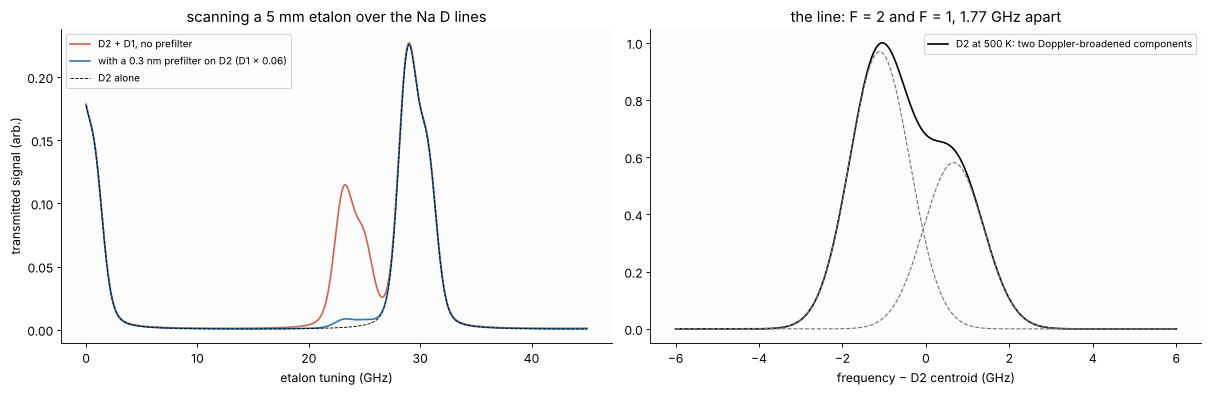

D1 appears 0.81 FSR = 24.2 GHz from D2 in the scan


In [3]:
d_scan = 5e6                              # nm
fsr_ghz = C_LIGHT/(2*d_scan*1e-9)/1e9
nu_D2 = C_LIGHT/(588.995e-9)/1e9          # GHz
nu_D1 = C_LIGHT/(589.592e-9)/1e9
w_dop = spc.doppler_fwhm(nu_D2, 500.0, 22.99)
print("FSR {:.2f} GHz, Doppler FWHM at 500 K {:.2f} GHz, resolution FSR/N = {:.2f} GHz".format(
    fsr_ghz, w_dop, fsr_ghz/spc.reflective_finesse(0.95)))
nu = np.linspace(-6, 6, 4001)             # GHz about the D2 centre of gravity
hfs = (-1.772*5/8, 1.772*3/8)             # F = 1 (weight 3) and F = 2 (weight 5) about the centroid
D2 = 3/8*spc.gaussian(nu, hfs[1], w_dop) + 5/8*spc.gaussian(nu, hfs[0], w_dop)
nu_all = np.linspace(-20, 40, 12001)
D2_all = (3/8*spc.gaussian(nu_all, hfs[1], w_dop) + 5/8*spc.gaussian(nu_all, hfs[0], w_dop))
# D1 relative to D2: nu_D1 - nu_D2 = -508 GHz; in the scan it appears at that offset modulo the FSR
off = (nu_D1 - nu_D2) % fsr_ghz
D1_all = 0.5*(3/8*spc.gaussian(nu_all, off + hfs[1], w_dop) + 5/8*spc.gaussian(nu_all, off + hfs[0], w_dop))
scan = np.linspace(0, 1.5, 1501)          # scan in units of the FSR (the piezo moves λ/2 per FSR)


def scanned(spec, nu_grid, R=0.95):
    out = []
    for s in scan:
        delta = 2*np.pi*(nu_grid/fsr_ghz - s)
        out.append(np.trapezoid(spec*spc.airy_transmission(delta, R), nu_grid))
    return np.array(out)


S_D2 = scanned(D2_all, nu_all)
S_D1 = scanned(D1_all, nu_all)
pre = 1/(1 + ((589.592 - 588.995)/(0.3/2))**2)        # Lorentzian prefilter centred on D2, FWHM 0.3 nm
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
ax[1].plot(nu, D2/D2.max(), color="k", label="D2 at 500 K: two Doppler-broadened components")
for h, w8 in zip(hfs, (5/8, 3/8)):
    ax[1].plot(nu, w8*spc.gaussian(nu, h, w_dop)/D2.max(), "--", color=GREY, lw=1)
ax[1].set_xlabel("frequency − D2 centroid (GHz)")
ax[1].set_title("the line: F = 2 and F = 1, 1.77 GHz apart")
ax[1].legend(fontsize=9)
ax[0].plot(scan*fsr_ghz, S_D2 + S_D1, color=RED, label="D2 + D1, no prefilter")
ax[0].plot(scan*fsr_ghz, S_D2 + pre*S_D1, color=BLUE, label="with a 0.3 nm prefilter on D2 (D1 × {:.2f})".format(pre))
ax[0].plot(scan*fsr_ghz, S_D2, color="k", lw=0.8, ls="--", label="D2 alone")
ax[0].set_xlabel("etalon tuning (GHz)")
ax[0].set_ylabel("transmitted signal (arb.)")
ax[0].set_title("scanning a 5 mm etalon over the Na D lines")
ax[0].legend(fontsize=9)
plt.show()
print("D1 appears {:.2f} FSR = {:.1f} GHz from D2 in the scan".format(off/fsr_ghz, off))

**Imaging.** Without scanning, an etalon in a diverging beam transmits
different wavelengths at different angles: in the focal plane of a lens
behind it, each line forms a set of rings, $\cos\theta_p = m_p\lambda/2nd$
(the Haidinger fringes of notebook 13). Two lines a little apart give two
interleaved sets of rings, and the shift of a ring measures the
wavelength difference. The textbook example is the **normal Zeeman
effect** of the red cadmium line (643.85 nm, a singlet transition): in a
magnetic field $B$ it splits into three components, shifted by
$0, \pm\mu_B B/h = \pm 14.0$ GHz/T. Seen across the field, the unshifted π
component has half the intensity and each σ component a quarter. A 3 mm
etalon ($R = 0.9$) behind a 150 mm lens shows the rings at $B = 0.5$ T.

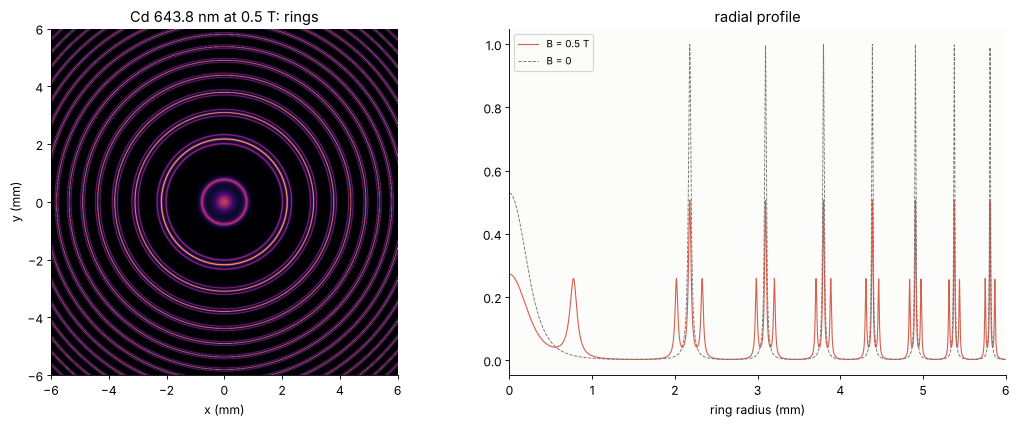

rings at B = 0: r² spacing 4.833 mm², FSR 50.0 GHz
σ rings around the π ring at 3.10 mm: shifts [-6.92  0.    7.03] GHz -> B = 0.498 T


In [4]:
lam_cd = 643.847                          # nm
d_im, f_lens, R_im = 3e6, 150.0, 0.90
nu_cd = C_LIGHT/(lam_cd*1e-9)/1e9         # GHz
B = 0.5
dz = 13.996*B                             # GHz
comps = ((0.0, 0.5), (+dz, 0.25), (-dz, 0.25))
rmax = 6.0                                # mm on the camera
xg = np.linspace(-rmax, rmax, 801)
X, Y = np.meshgrid(xg, xg)
theta = np.arctan(np.hypot(X, Y)/f_lens)
img = np.zeros_like(X)
for sh, w8 in comps:
    lam_c = C_LIGHT/((nu_cd + sh)*1e9)*1e9
    img += w8*spc.airy_transmission(4*np.pi*d_im*np.cos(theta)/lam_c, R_im)
r = np.linspace(0, rmax, 3000)
th_r = np.arctan(r/f_lens)
prof = sum(w8*spc.airy_transmission(4*np.pi*d_im*np.cos(th_r)/(C_LIGHT/((nu_cd + sh)*1e9)*1e9), R_im)
           for sh, w8 in comps)
prof0 = spc.airy_transmission(4*np.pi*d_im*np.cos(th_r)/lam_cd, R_im)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
ax1.imshow(img, extent=(-rmax, rmax, -rmax, rmax), cmap="inferno", origin="lower")
ax1.set_xlabel("x (mm)")
ax1.set_ylabel("y (mm)")
ax1.set_title("Cd 643.8 nm at 0.5 T: rings")
ax2.plot(r, prof, color=RED, lw=1, label="B = 0.5 T")
ax2.plot(r, prof0, color=GREY, lw=0.8, ls="--", label="B = 0")
ax2.set_xlim(0, rmax)
ax2.set_xlabel("ring radius (mm)")
ax2.set_title("radial profile")
ax2.legend(fontsize=9)
plt.show()
# measure the splitting from the squared radii of the B = 0 rings and of the σ rings
pk0 = np.where((prof0[1:-1] > prof0[:-2]) & (prof0[1:-1] >= prof0[2:]) & (prof0[1:-1] > 0.5))[0] + 1
r0 = r[pk0]
dr2 = np.mean(np.diff(r0**2))
pk = np.where((prof[1:-1] > prof[:-2]) & (prof[1:-1] >= prof[2:]) & (prof[1:-1] > 0.05))[0] + 1
rings = r[pk]
# the σ ring just outside each π ring belongs to the next lower frequency within the order;
# frequency shift = FSR (r_σ² − r_π²)/Δ(r²)
fsr_im = C_LIGHT/(2*d_im*1e-9)/1e9
pi_r = rings[np.argmin(np.abs(rings - r0[1]))]
near = np.sort(rings[np.abs(rings - pi_r) < 0.4*(r0[2] - r0[1])])
shifts = (near**2 - pi_r**2)/dr2*fsr_im
print("rings at B = 0: r² spacing {:.3f} mm², FSR {:.1f} GHz".format(dr2, fsr_im))
print("σ rings around the π ring at {:.2f} mm: shifts {} GHz -> B = {:.3f} T".format(
    pi_r, np.round(shifts, 2), np.mean(np.abs(shifts[np.abs(shifts) > 1]))/13.996))

**Scanning.** The two hyperfine components of D2, 1.77 GHz apart and each
1.7 GHz wide, show as a peak with a shoulder, repeated after one free
spectral range of 30 GHz. D1 lands 24 GHz (0.81 FSR) into the same scan,
where it can be mistaken for another component of D2. A 0.3 nm prefilter
on D2 suppresses it to 6 %. Sources narrower than the Doppler width (atomic beams, or saturated absorption
with lasers) resolve the components fully.

**Imaging.** Without field, the Cd line forms single rings whose squared
radii are equally spaced: $\Delta(r^2) = 4.83$ mm² per order, i.e. per free
spectral range of 50 GHz. At 0.5 T every ring becomes a triplet: the
π ring in place, the two σ rings on either side. Their squared radii measure the
splitting, −6.9 and +7.0 GHz, which gives back $B = 0.50$ T from
$\mu_B B/h$. This is the classic experiment for the Bohr magneton; with a
polarizer, the π and σ rings can be separated, as they are polarized
along and across the field.

## 3. Interference filters

An interference filter is a Fabry–Perot made of thin films: two
dielectric mirrors $(HL)^N$ around a spacer of one or a few half waves.
The order is tiny ($m = 1$ or 2), so the free spectral range is huge
(hundreds of nm, with side bands blocked by extra coatings or coloured
glass), and the bandwidth is set by the mirror reflectance, i.e. by the
number of layers. Below: $(HL)^N\,HH\,(LH)^N$ with quarter-wave TiO₂ (H)
and SiO₂ (L) at 589.3 nm, on glass, computed with `thin_films`.

Tilted by $\theta$, the round trip phase in the spacer shrinks with
$\cos\theta_\mathrm{spacer}$, and the passband moves to the blue as

$$\lambda(\theta) = \lambda_0\sqrt{1 - \sin^2\theta/n_\mathrm{eff}^2},$$

with an effective index $n_\mathrm{eff}$ between the indices of the
layers. Tilt-tuning uses this; a filter in a converging beam suffers from
it, because its passband is the average over the cone of angles.

tilt shifts (s, p) in nm: [[0.0, 0.0], [-2.59, -2.6], [-10.1, -10.18], [-21.76, -22.15]]
effective index from the unpolarized shifts: [1.852 1.852 1.849] (layers 2.35 and 1.46)


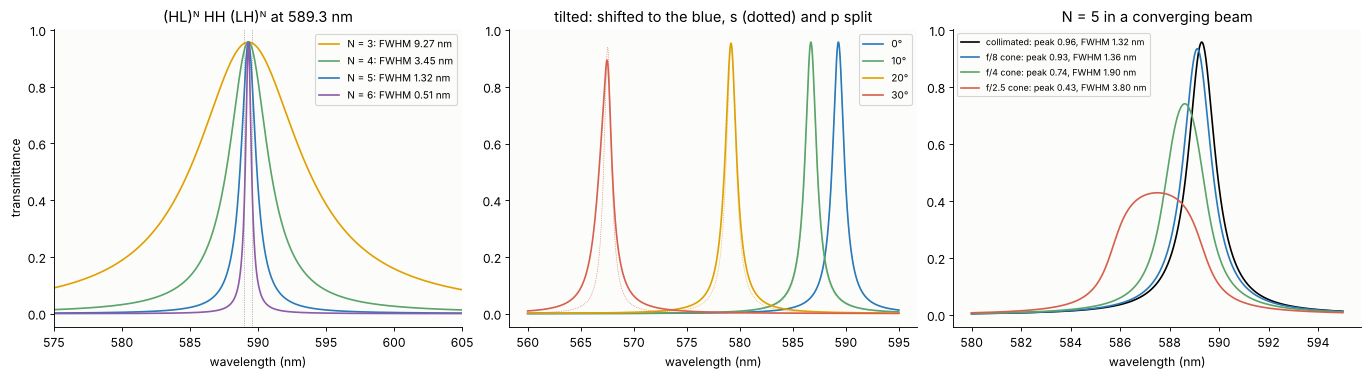

In [5]:
def filter_stack(N, spacer_halfwaves=1, lam0=LAM0, scale=1.0):
    n = [N_H, N_L]*N + [N_H]*(2*spacer_halfwaves) + [N_L, N_H]*N
    t = [scale*lam0/(4*x) for x in n]
    return n, t


lam_f = np.linspace(560, 620, 3001)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
fw_N = {}
for N, c in ((3, ORANGE), (4, GREEN), (5, BLUE), (6, PURPLE)):
    n_s, t_s = filter_stack(N)
    T = np.array([stack_RTA(n_s, t_s, l, n_in=1.0, n_sub=1.52)[1] for l in lam_f])
    fw_N[N] = spc.fwhm(lam_f, T)
    ax[0].plot(lam_f, T, color=c, label="N = {}: FWHM {:.2f} nm".format(N, fw_N[N]))
ax[0].axvline(588.995, color=GREY, lw=0.6, ls=":")
ax[0].axvline(589.592, color=GREY, lw=0.6, ls=":")
ax[0].set_xlim(575, 605)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("transmittance")
ax[0].set_title("(HL)ᴺ HH (LH)ᴺ at 589.3 nm")
ax[0].legend(fontsize=9)

# tilt: s, p and unpolarized, for N = 5
n5, t5 = filter_stack(5)
lam_t = np.linspace(560, 595, 3501)
angles = np.radians([0, 10, 20, 30])
centres = []
for a, c in zip(angles, (BLUE, GREEN, ORANGE, RED)):
    Ts = np.array([stack_RTA(n5, t5, l, angle=a, n_sub=1.52, pol="s")[1] for l in lam_t])
    Tp = np.array([stack_RTA(n5, t5, l, angle=a, n_sub=1.52, pol="p")[1] for l in lam_t])
    centres.append((lam_t[np.argmax(Ts)], lam_t[np.argmax(Tp)]))
    ax[1].plot(lam_t, 0.5*(Ts + Tp), color=c, label="{:.0f}°".format(np.degrees(a)))
    ax[1].plot(lam_t, Ts, color=c, lw=0.6, ls=":")
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_title("tilted: shifted to the blue, s (dotted) and p split")
ax[1].legend(fontsize=9)
centres = np.array(centres)
lc = centres.mean(axis=1)
n_eff = np.sin(angles[1:])/np.sqrt(1 - (lc[1:]/lc[0])**2)
print("tilt shifts (s, p) in nm:", np.round(centres - centres[0], 2).tolist())
print("effective index from the unpolarized shifts: {} (layers {:.2f} and {:.2f})".format(
    np.round(n_eff, 3), N_H, N_L))

# converging beams: average the s and p transmission over a uniformly filled cone
lam_c = np.linspace(580, 595, 1501)
T_ang = {}
th_grid = np.radians(np.linspace(0, 15, 31))
for a in th_grid:
    Ts = np.array([stack_RTA(n5, t5, l, angle=a, n_sub=1.52, pol="s")[1] for l in lam_c])
    Tp = np.array([stack_RTA(n5, t5, l, angle=a, n_sub=1.52, pol="p")[1] for l in lam_c])
    T_ang[a] = 0.5*(Ts + Tp)
for fnum, c in ((None, "k"), (8, BLUE), (4, GREEN), (2.5, RED)):
    if fnum is None:
        Tc = T_ang[0.0]
        lab = "collimated"
    else:
        th_max = np.arcsin(1/(2*fnum))
        w8 = np.array([np.sin(a) if a <= th_max else 0.0 for a in th_grid])   # area weight of the ring
        w8[0] = 0.25*np.sin(th_grid[1])
        Tc = sum(w*T_ang[a] for w, a in zip(w8, th_grid))/w8.sum()
        lab = "f/{:g} cone".format(fnum)
    ax[2].plot(lam_c, Tc, color=c, label="{}: peak {:.2f}, FWHM {:.2f} nm".format(lab, Tc.max(),
                                                                               spc.fwhm(lam_c, Tc)))
ax[2].set_xlabel("wavelength (nm)")
ax[2].set_title("N = 5 in a converging beam")
ax[2].legend(fontsize=8)
plt.show()

Each extra pair of layers on both mirrors narrows the pass band by a
factor of about 2.6 (9.3, 3.5, 1.3 and 0.5 nm for $N$ = 3 to 6), at a
peak transmission of 96 % (the uncoated back side of the glass costs the
rest). With $N = 6$ the filter would separate the two sodium D lines.
The passband moves to the blue by 2.6 nm at 10°, 10 nm at 20° and 22 nm at
30°, with $n_\mathrm{eff} = 1.85$ from all three angles. At larger angles s
and p begin to part (by 0.4 nm at 30°), as the layers' effective indices differ
for the two polarizations.

A converging beam averages over the cone. At f/8 (3.6°) the filter
loses 3 % of its peak and broadens from 1.32 to 1.36 nm; at f/4 the peak
drops to 74 % and moves by 0.7 nm; at f/2.5 it is a broad bump at 43 %.
A narrow filter belongs in a collimated beam or a slow one. As a rule of
thumb, the shift at the rim of the cone, $\lambda\theta^2/2n_\mathrm{eff}^2$,
should stay below the FWHM, i.e. $\theta < n_\mathrm{eff}\sqrt{2\,\mathrm{FWHM}/\lambda}$,
7° (f/4) for this filter.

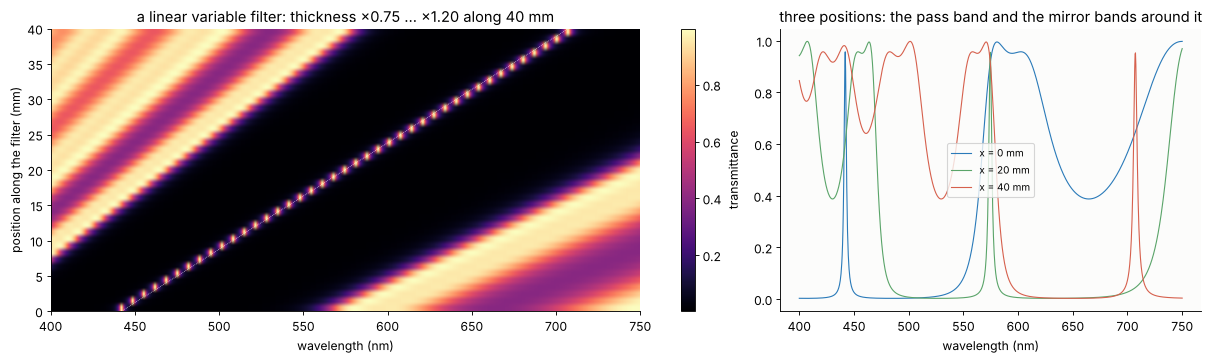

centre wavelengths at 0, 10, 20, 30, 40 mm (nm): [442.0, 508.2, 574.6, 640.8, 707.3]
dispersion of the wedge: 6.63 nm/mm, FWHM at 0 / 40 mm: 2.61 / 4.18 nm


In [6]:
# linear variable filter: all layer thicknesses grow linearly along the filter
x_lvf = np.linspace(0, 40, 41)             # mm
scale = np.linspace(0.75, 1.20, len(x_lvf))
lam_l = np.linspace(400, 750, 1001)
T_map = np.empty((len(x_lvf), len(lam_l)))
peaks = []
for i, sc in enumerate(scale):
    n_s, t_s = filter_stack(4, scale=sc)
    T_map[i] = [stack_RTA(n_s, t_s, l, n_in=1.0, n_sub=1.52)[1] for l in lam_l]
    peaks.append(lam_l[np.argmax(np.where(np.abs(lam_l - LAM0*sc) < 0.1*LAM0*sc, T_map[i], 0))])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained", gridspec_kw={"width_ratios": [1.4, 1]})
im = ax[0].imshow(T_map, extent=(lam_l[0], lam_l[-1], x_lvf[0], x_lvf[-1]), aspect="auto", origin="lower",
                  cmap="magma")
ax[0].plot(peaks, x_lvf, color="w", lw=0.6, ls=":")
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("position along the filter (mm)")
ax[0].set_title("a linear variable filter: thickness ×0.75 … ×1.20 along 40 mm")
fig.colorbar(im, ax=ax[0], label="transmittance")
for i, c in zip((0, 20, 40), (BLUE, GREEN, RED)):
    ax[1].plot(lam_l, T_map[i], color=c, lw=1, label="x = {:.0f} mm".format(x_lvf[i]))
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_title("three positions: the pass band and the mirror bands around it")
ax[1].legend(fontsize=9)
plt.show()
print("centre wavelengths at 0, 10, 20, 30, 40 mm (nm):", np.round(peaks[::10], 1).tolist())
print("dispersion of the wedge: {:.2f} nm/mm, FWHM at 0 / 40 mm: {:.2f} / {:.2f} nm".format(
    np.polyfit(x_lvf, peaks, 1)[0], spc.fwhm(lam_l[np.abs(lam_l - peaks[0]) < 20], T_map[0][np.abs(lam_l - peaks[0]) < 20]),
    spc.fwhm(lam_l[np.abs(lam_l - peaks[-1]) < 20], T_map[-1][np.abs(lam_l - peaks[-1]) < 20])))

If the layers grow thicker along the substrate, the pass band moves with
them: here linearly from 442 to 707 nm along 40 mm, 6.6 nm/mm, with a FWHM
of 2.6 nm in the blue to 4.2 nm in the red (the bandwidth scales with the
wavelength). On top of a detector array such a wedge is a spectrometer
without moving parts or a grating, used in compact hyperspectral cameras
(notebook 115). The map also shows the limits of a simple filter: away
from the pass band the quarter-wave mirrors stop reflecting, and light
leaks through on both sides, which in practice extra blocking coatings
remove.

## 4. The Lyot filter and the Šolc filter

A birefringent plate of thickness $d$ between parallel polarizers, its
axes at 45°, transmits $\cos^2(\pi\Delta n\,d/\lambda)$: a channelled
spectrum with the period $\lambda^2/(\Delta n\,d)$. Lyot (1933) stacked
such stages with thicknesses $d, 2d, 4d, \ldots, 2^{N-1}d$, each between
polarizers. The product

$$T = \prod_{k=0}^{N-1}\cos^2\left(\frac{\pi\Delta n\,2^k d}{\lambda}\right)$$

keeps the peaks of the thickest plate only where all thinner plates also
transmit: the free spectral range is that of the thinnest plate,
$\lambda^2/\Delta n\,d$, the bandwidth is set by the thickest,
$0.886\,\lambda^2/(2^N\Delta n\,d)$ for many stages. A prefilter isolates one peak. For the
solar Hα line (656.28 nm), with calcite ($\Delta n = 0.172$, taken
constant), a 1.25 mm thinnest plate (adjusted so that Hα is an integer order of
every plate) gives an FSR of 2 nm, and six stages (the thickest 40 mm) a
bandwidth of about 0.03 nm. The Jones matrices of
`polarization.jones` give the same as the product, and the Šolc filter
(Šolc 1953), with $N$ equal plates at alternating azimuths
$\pm\pi/4N$ between crossed polarizers and no inner polarizers, is computed
the same way.

thinnest plate 1.2515 mm
Jones against the product formula: max difference 4.4e-16


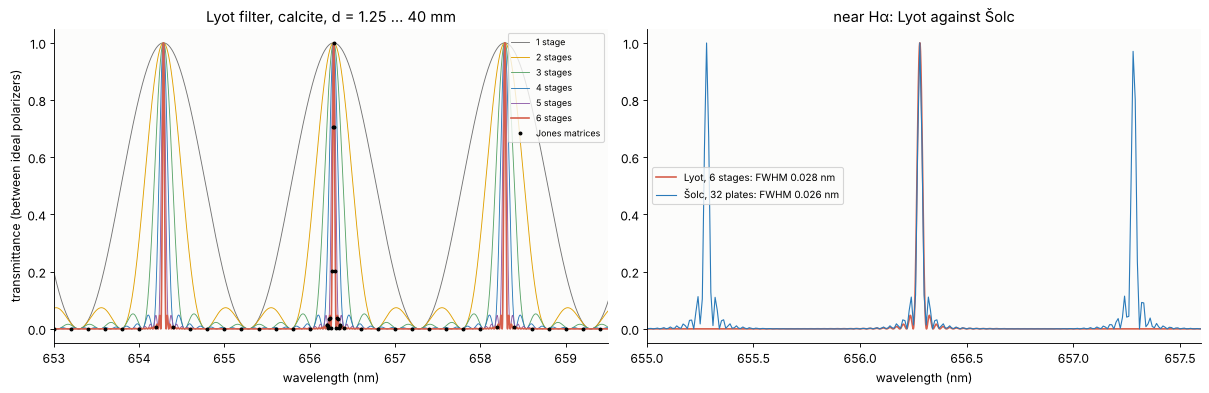

Lyot: peak at 656.280 nm, FSR 1.99 nm (λ²/Δn d = 2.00), FWHM 0.0277 nm (0.886 λ²/(2^N Δn d) = 0.0277)


In [7]:
lam_h = np.linspace(652, 660, 16001)
dn_cal, Nst = 0.172, 6
d1 = round(1.25e6*dn_cal/656.28)*656.28/dn_cal   # an integer order at Hα in every plate
print("thinnest plate {:.4f} mm".format(d1*1e-6))
T_lyot = spc.lyot_transmission(lam_h, d1, dn_cal, Nst)
# Jones check on a coarse grid
lam_j = np.concatenate([lam_h[::400], np.linspace(656.20, 656.36, 17)])
Pol = jones.J_polarizer(1.0, 0.0)
Tj = []
for l in lam_j:
    J = np.eye(2)
    for k in range(Nst):
        J = Pol @ jones.rotate(jones.J_WP(2*np.pi*dn_cal*d1*2**k/l), np.pi/4) @ J
    E = J @ np.array([1.0, 0.0])
    Tj.append(np.sum(np.abs(E)**2))
print("Jones against the product formula: max difference {:.1e}".format(
    np.max(np.abs(np.array(Tj) - spc.lyot_transmission(lam_j, d1, dn_cal, Nst)))))
# Šolc (folded): N equal plates of the thickest Lyot plate's total retardance? use 2^(N-1) d / ... :
N_solc = 32
# each plate a half-wave plate at Hα (an odd multiple of π), 2.5 mm thick:
d_solc = (np.round(2.5e6*dn_cal/656.28 - 0.5) + 0.5)*656.28/dn_cal
rho = np.pi/(4*N_solc)
T_solc = []
Pv = jones.J_polarizer(0.0, 1.0)
for l in lam_h[::20]:
    G = 2*np.pi*dn_cal*d_solc/l
    J = np.eye(2)
    for k in range(N_solc):
        J = jones.rotate(jones.J_WP(G), rho if k % 2 == 0 else -rho) @ J
    E = Pv @ J @ np.array([1.0, 0.0])
    T_solc.append(np.sum(np.abs(E)**2))
T_solc = np.array(T_solc)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), layout="constrained")
for k, c in zip(range(1, Nst + 1), (GREY, ORANGE, GREEN, BLUE, PURPLE, RED)):
    ax[0].plot(lam_h, spc.lyot_transmission(lam_h, d1, dn_cal, k), color=c, lw=0.8 if k < Nst else 1.5,
               label="{} stage{}".format(k, "s" if k > 1 else ""))
ax[0].plot(lam_j, Tj, "ko", ms=2.5, label="Jones matrices")
ax[0].set_xlim(653, 659.5)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("transmittance (between ideal polarizers)")
ax[0].set_title("Lyot filter, calcite, d = 1.25 … 40 mm")
ax[0].legend(fontsize=8, loc="upper right")
pk = np.argmin(np.abs(lam_h - 656.28))
sel = np.abs(lam_h - lam_h[np.argmax(np.where(np.abs(lam_h - 656.28) < 0.5, T_lyot, 0))]) < 0.3
ax[1].plot(lam_h, T_lyot, color=RED, label="Lyot, 6 stages: FWHM {:.3f} nm".format(
    spc.fwhm(lam_h[sel], T_lyot[sel])))
ls = lam_h[::20]
sel2 = np.abs(ls - ls[np.argmax(np.where(np.abs(ls - 656.28) < 0.5, T_solc, 0))]) < 0.3
ax[1].plot(ls, T_solc, color=BLUE, lw=1, label="Šolc, {} plates: FWHM {:.3f} nm".format(
    N_solc, spc.fwhm(ls[sel2], T_solc[sel2])))
ax[1].set_xlim(655.0, 657.6)
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_title("near Hα: Lyot against Šolc")
ax[1].legend(fontsize=9)
plt.show()
i_pk = np.argmax(np.where(np.abs(lam_h - 656.28) < 0.6, T_lyot, 0))
print("Lyot: peak at {:.3f} nm, FSR {:.2f} nm (λ²/Δn d = {:.2f}), FWHM {:.4f} nm (0.886 λ²/(2^N Δn d) = {:.4f})".format(
    lam_h[i_pk], np.diff(lam_h[np.where((T_lyot[1:-1] > T_lyot[:-2]) & (T_lyot[1:-1] >= T_lyot[2:]) & (T_lyot[1:-1] > 0.9))[0] + 1]).mean(),
    656.28**2/(dn_cal*d1), spc.fwhm(lam_h[sel], T_lyot[sel]), 0.886*656.28**2/(2**Nst*dn_cal*d1)))

The Jones matrix products and the product formula agree to $10^{-16}$.
Each stage halves the width of the peaks and suppresses every second one
of the next thinner stage. With six stages the peak at Hα has a FWHM of
0.028 nm ($0.886\,\lambda^2/2^N\Delta n\,d$), and its neighbours are
2 nm away, where a 1 nm interference prefilter removes them. The Šolc
filter with 32 half-wave plates of 2.5 mm reaches about the same width (0.026 nm) with
only two polarizers, which saves the light that six polarizers absorb, but
it has side lobes of about 10 % and its free spectral range is set by the
plate thickness alone (1 nm here).

Real Lyot filters (and their modern version, liquid-crystal tunable
filters) are tuned by rotating half-wave plates or by liquid-crystal
retarders in each stage, and are temperature stabilized: the birefringence
of calcite changes by about $10^{-5}$ per kelvin, which shifts a 40 mm stage
by a full order for less than two kelvin.

## 5. Resolving power and étendue

Jacquinot's 1954 comparison: for the same beam area, how much light
from an extended source does each instrument accept at a given
resolving power? An instrument that selects wavelengths by an angle-dependent
phase (Fabry–Perot, Michelson) passes a cone in which the phase changes by
less than the resolution: $\theta^2/2 < 1/R$, so $\Omega = 2\pi/R$. An
interference filter has the same law with the effective index,
$\Omega = 2\pi n_\mathrm{eff}^2/R$. A grating spectrometer passes only its
slit, $\Omega = wh/f^2$ with $w$ set by $R$ (notebooks 110 and 111). A Lyot
filter's plates change their retardance with the angle too; the simple
plates computed here accept a few times $2\pi/R$, and "wide-field"
designs (split elements with crossed axes and a half-wave plate between them)
gain a further factor of about 100.

In [8]:
R_vals = {"interference filter N = 5": LAM0/fw_N[5],
          "Lyot, 6 stages": 656.28/spc.fwhm(lam_h[sel], T_lyot[sel]),
          "Czerny–Turner, 40 µm slit (nb 110)": 589.3/0.275,
          "Fabry–Perot, 5 mm, dielectric": LAM0/(fsr_nm/results["(HL)⁵H dielectric"][3]),
          "FTS, L = 2 cm at 2000 cm⁻¹ (nb 111)": 2000/(1.207/4)}
print("{:38s} {:>12s} {:>14s}".format("instrument", "R", "Ω (sr)"))
for name, Rv in R_vals.items():
    if "grating" in name or "Czerny" in name:
        Om = 0.040*5.0/100.0**2                       # slit 40 µm x 5 mm, f = 100 mm
    elif "filter" in name and "Lyot" not in name:
        Om = 2*np.pi*np.mean(n_eff)**2/Rv
    else:
        Om = 2*np.pi/Rv
    print("{:38s} {:12.3g} {:14.3g}".format(name, Rv, Om))

instrument                                        R         Ω (sr)
interference filter N = 5                       448         0.0481
Lyot, 6 stages                             2.37e+04       0.000265
Czerny–Turner, 40 µm slit (nb 110)         2.14e+03          2e-05
Fabry–Perot, 5 mm, dielectric              5.83e+06       1.08e-06
FTS, L = 2 cm at 2000 cm⁻¹ (nb 111)        6.63e+03       0.000948


The product $R\,\Omega$ is the figure of merit for an extended source.
It is $2\pi$ for the Fabry–Perot and the FTS (both select by an angle-dependent
phase), $2\pi n_\mathrm{eff}^2 \approx 22$ for an interference filter,
whose light travels in high index layers, and only 0.04 for the
Czerny–Turner with its 40 µm × 5 mm slit. At the same resolving power a
Fabry–Perot accepts about 150 times the light of the grating spectrometer,
Jacquinot's argument for interferometers. The grating's strength is the
other side of the coin: it records a wide band at once on an array detector,
while a Fabry–Perot sees one free spectral range and a filter one band.

## Summary

- **Fabry–Perot:** FSR $1/2nd$, finesse $\pi\sqrt R/(1 - R)$, resolving
  power $m\mathcal F$. A 5 mm etalon with silver mirrors: finesse 24, peak
  68 % (absorption); with a dielectric stack: finesse 344, $R = 5.8\times10^6$.
  Plates bowed by $\lambda/M$ limit the finesse to $M/2$, combining in
  quadrature with the reflective finesse.
- **Scanning and imaging:** the Na D2 hyperfine doublet (1.77 GHz, under
  1.7 GHz Doppler widths) at 0.5 GHz resolution; overlapping orders (D1
  0.81 FSR away) need a prefilter. The Zeeman rings of Cd give back
  $B = 0.50$ T from $\mu_B B/h = 14$ GHz/T.
- **Interference filters:** $(HL)^N HH (LH)^N$, FWHM from 9 nm ($N = 3$) to
  0.5 nm ($N = 6$); blue shift $\lambda_0\sqrt{1 - \sin^2\theta/n_\mathrm{eff}^2}$
  with $n_\mathrm{eff} = 1.85$; an f/4 cone costs a quarter of the peak. A wedge
  makes a linear variable filter (6.6 nm/mm).
- **Lyot and Šolc:** products of $\cos^2$ (checked with Jones matrices): FSR from
  the thinnest plate, FWHM $0.886\,\lambda^2/2^N\Delta n\,d$ from the
  thickest, 0.028 nm at Hα with six calcite stages.
- **Étendue:** $R\Omega = 2\pi$ for Fabry–Perot and FTS,
  $2\pi n_\mathrm{eff}^2$ for filters, about 0.04 for a slit spectrometer.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 57 s


## References

- J. M. Vaughan, *The Fabry–Perot Interferometer*, Adam Hilger (1989).
- G. Hernandez, *Fabry–Perot Interferometers*, Cambridge University
  Press (1986).
- H. A. Macleod, *Thin-Film Optical Filters*, 5th ed., CRC Press (2018).
- B. Lyot, "Optical apparatus with wide field using interference of
  polarized light", C. R. Acad. Sci. 197, 1593 (1933); "Le filtre
  monochromatique polarisant et ses applications en physique solaire",
  Ann. Astrophys. 7, 31–79 (1944).
- I. Šolc, "Birefringent chain filters", J. Opt. Soc. Am. 55, 621–625
  (1965).
- J. W. Evans, "The birefringent filter", J. Opt. Soc. Am. 39, 229–242
  (1949).
- P. Jacquinot, "The luminosity of spectrometers with prisms, gratings, or
  Fabry–Perot etalons", J. Opt. Soc. Am. 44, 761–765 (1954).
- P. B. Johnson and R. W. Christy, "Optical constants of the noble
  metals", Phys. Rev. B 6, 4370–4379 (1972).
- D. A. Steck, *Sodium D Line Data*, available online (revision 2.3,
  2024), for the hyperfine splitting.